# 02 퍼셉트론 & 딥러닝 기초

- 단층 퍼셉트론
  - 단층 퍼셉트론의 한계
- 다층 퍼셉트론
- 딥러닝 모델의 학습 방법
  - 순전파와 역전파, 연쇄 법칙
  - 손실 함수의 정의와 종류
  - 활성화 함수의 정의와 종류
  - 옵티마이저의 정의와 종류

## <span style="background-color:#fae0f0; color:#c0156d; padding:4px; border-radius:5px;"> 1. 인공신경망의 시작: 퍼셉트론 </span>

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 1.1 인공신경망이란? (Artificial Neural Network) </span>

#### 1. **인공신경망**
1. **개념** : <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> 우리 뇌의 신경망을 모방한 모델 </span>
   - <span style="color:blue">신경망</span> : 뇌를 구성하는 신경 세포끼리 서로 연결되어 정보를 처리하는 구조
   - **생물학적 뉴런의 정보 처리** : 가지돌기(외부 전기신호 수신) -> 모인 신호가 일정 크기 이상이면 -> 축삭돌기(신호 전달)
2. **인공신경망의 연결 방식**
   - **입력**들 $x_1, x_2, …, x_n$을 받아 각각 **가중치** $w_1, w_2, …, w_n$와 **편향** $b$ 적용
   - 종합한 값을 **활성화 함수**에 넘김 (활성화 함수 기준: 임계값)
      - 기준 미달 -> **0에 가깝게** 죽여서 내보냄
      - 기준 통과 -> **유의미한 값**으로 살려서 내보냄
    - output 출력

#### 2. **퍼셉트론** (Perceptron)
1. **개념** : <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> 초기 형태의 인공신경망, 딥러닝의 기원이 되는 선형 이진 분류기 </span> (Linear Binary Classifier)
2. **퍼셉트론의 출력값을 구하는 절차** : 입력 -> 가중합 -> 활성화 함수 -> 출력
   1. 입력 : 입력값과 가중치를 곱함 ($x_1w_1$)
   2. 가중합 : 곱한 값들의 총합을 구함 ($x_1w_1 + x_2w_2 + ⋯ + x_nw_n$) (편향 포함은 옵션)
   3. 활성화 함수 & 출력 : 총합이 임계값($\theta$)을 넘으면 1, 안 넘으면 0 출력
      - 이 경우 활성화 함수는 **Step 함수** (어떤 활성화 함수를 쓰느냐에 따라 출력이 달라짐)
   - **Training(학습)** : 원하는 출력값 내보내도록 **가중치를 조정**하는 작업

#### 3. **용어 정리**
1. **가중치**(weight, $w_n$)
   1. 역할 : 입력값이 출력값에 주는 **영향력(중요도)** 결정
   2. 각 입력값 당 각각의 가중치 O, 값이 클수록 해당 입력이 중요하단 의미
2. **활성화 함수**
   1. 퍼셉트론은 임계값을 넘으면 1, 아니면 0을 출력하므로 **계단 함수**(Step) 사용
   2. 이후 발전된 신경망들은 계단 함수 외에도 다양한 활성화 함수 사용
      * ex. Sigmoid : 계단식의 **미분 불가** 문제 해결 (로지스틱 회귀에서 사용)
      * ex. ReLU : 음수는 0으로, 양수 계산 속도 이점, **기울기 소실** 문제 해결
      * ex. leaky ReLU : ReLU의 음수 부분에 미세한 기울기를 줌, x<0일 때의 Dying ReLU 해결 (but 실무에서는 ReLU 많이 씀)
3. **임계값**(Threshold, $\theta$)
   1. 활성화 함수에 사용되는 기준 값
$$\begin{aligned}&\text{if } \sum_{i}^{n} w_i x_i \ge \theta \rightarrow y=1 \\&\text{if } \sum_{i}^{n} w_i x_i < \theta \rightarrow y=0\end{aligned}$$
4. **편향**(bias)
   1. 임계값을 좌변으로 넘기면 편향 b로 표현 가능
   2. 그림으로 표현 시 입력값 1에 편향 $b$가 곱해진 형태
   3. => **임계값과 편향은 표현의 차이임** 오늘날 딥러닝에서는 편향 개념을 주로 사용

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 1.2 단층 퍼셉트론과 그 한계 (Single-Layer Perceptron) </span>

#### 1. **개념**
- **입력층**(값을 보내는 단계) -> **출력층**(값을 받아서 출력하는 단계)으로만 이루어진 퍼셉트론

#### 2. **논리 게이트 (Logic Gate) 구현**
- 논리 게이트란?
  - 디지털 회로에서 기본적인 논리 연산을 수행하는 구성 요소
  - 게이트 연산에 쓰이는 것은 n개의 입력값과 하나의 출력값
  - 종류 : `AND`, `OR`, `NOT`, `NAND`, `NOR`, `XOR` 등 (조합하면 복잡한 논리 회로 구성 가능)
- 단층 퍼셉트론으로 **AND, NAND, OR**는 쉽게 구현 가능

#### 3. **대표적인 논리 게이트**
- **AND 게이트** : 입력값이 모두 1인 경우에만 출력값이 1인 구조
- 나머지는 원리가 똑같고 **숫자(가중치, 편향)만 바뀜**

    | 게이트 |         조건         | 가중치·편향 예시 [w1, w2, b] |
    |:------:|:--------------------:|:----------------------------:|
    | AND    | 둘 다 1일 때만 1     | [0.5, 0.5, -0.7]             |
    | OR     | 둘 다 0일 때만 0     | [0.6, 0.6, -0.5]             |
    | NAND   | 둘 다 1일 때만 0     | [-0.5, -0.5, 0.7]            |
    | XOR    | 서로 다를 때만 1     | 가능 조합 없음 |

  - NAND는 AND의 부호를 뒤집은 것
  - AND의 가중치 조합은 여러 개 가능 (ex. [0.5, 0.5, -0.8], [1.0, 1.0, -1.0])

#### 4. **단층 퍼셉트론의 한계**
- XOR 게이트 구현 X
  - <span style="color:blue">**퍼셉트론** = 입력값과 가중치의 **선형 결합**</span>
  - **단층 퍼셉트론**은 직선 하나로 두 영역을 나눌 수 있는 **선형 분류 문제**만 구현 가능
    - AND : 직선 하나로 분리 가능
    - XOR : 직선말고 **곡선/비선형 영역**으로만 분리 가능 -> 단층 퍼셉트론으로 불가
  - 따라서 **다층 퍼셉트론**이 필요!

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 1.3 다층 퍼셉트론 (Multi-Layer Perceptron, MLP) </span>

#### 1. **개념**
- 입력층과 출력층 사이에 **하나 이상의 은닉층**이 추가된 퍼셉트론
  - **심층 신경망**(DNN) : 은닉층이 **2개 이상**인 신경망
  - **딥러닝** : 심층 신경망을 학습시킴 (가중치를 스스로 찾도록)
- **XOR 게이트**도 기존 AND, NAND, OR 게이트를 조합해, 즉 **층을 쌓아** 구현 가능
  - 은닉층의 두 뉴런이 각각 **NAND, OR** 계산 -> 출력층이 두 결과에 **AND** 적용 = **XOR**
  - 뉴런 두 개짜리 은닉층 하나면 충분
- <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> 근데 층을 쌓는 것만으로는 비선형성이 생기지 않음 </span>
  - 활성화 함수 없이 가중합과 편향만 계산하면, 여러 층도 결국 하나의 선형 연산으로 합쳐짐
$$y = W_2(W_1x + b_1) + b_2 = (W_2W_1)x + (W_2b_1 + b_2) = Wx + b$$
  - 이러면 결정 경계는 여전히 직선 -> XOR 구현 불가
- **MLP가 XOR을 구현할 수 있는 이유** : 은닉층에서 **비선형 활성화 함수**를 적용해 새로운 특징을 만들고, 다음 층에서 그 특징들을 조합하기 때문
$$h = \sigma(W_1x + b_1), \quad y = W_2h + b_2 \quad (\sigma : 비선형\ 활성화\ 함수)$$
  - **단층 퍼셉트론도 계단 함수(비선형)를 사용**하지만, 가중합 한 번에 임계값을 적용하므로 결정 경계는 직선. 
  - 다층 구조는 **중간 결과를 다시 조합**할 수 있다는 차이가 있음

## <span style="background-color:#fae0f0; color:#c0156d; padding:4px; border-radius:5px;"> 2. 딥러닝 모델은 어떻게 학습할까? </span>

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.1 순전파와 역전파 (Forward & Backward Propagation) </span>

#### 1. **학습 알고리즘의 기본 구조**
1. **순전파**를 통해 입력값으로부터 예측 수행
2. **오차(손실) 계산**을 통해 예측 정확도 측정
3. **역전파**를 통해 출력층에서 다시 입력층 방향으로 오차 전달
4. **가중치** 업데이트
5. 1-4 반복 -> 반복을 통해 오차값이 0에 가까워지게 됨

- 이 순전파/역전파 과정이 일어나는 방식이 **연쇄법칙**

#### 2. **연쇄법칙 (Chain Rule)**
- **개념** : <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> 합성함수의 미분은 각 함수의 미분의 곱으로 나타낼 수 있다 </span>
  - <span style="color:blue">입력값이 최종 출력에 얼마나 영향을 미쳤는지 계산하려면, 각 층이 다음 층에 미친 영향을 순서대로 곱해나가야 하기 때문</span>
- **목적** : 모델의 **오차 감소**를 위해 역전파 과정에서 **각 가중치가 최종 손실에 얼마나 기여**했는지 계산
- **손실 함수** : 예측값과 실제값의 차이를 수치로 표현한 것
- **연쇄법칙으로 구하는 기울기** : 손실 함수를 줄이기 위해 **가중치를 어떻게 바꿀까?** 를 알려주는 신호

#### 3. **기울기 소실 문제 (Vanishing Gradient Problem)**
- **개념** : <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> 은닉층이 많고 각 단계의 미분값이 1보다 작으면, 곱해질수록 기울기가 0에 가까워지는 문제 </span>
$$0.25 \times 0.25 \times 0.25 \times \cdots \approx 0$$
  - 0.25는 시그모이드 미분의 **최댓값**
- **영향** : 앞쪽 층의 가중치가 거의 업데이트되지 않아 **학습이 제대로 이뤄지지 않음**
- 2.3 활성화 함수에서 해결책(ReLU)이 다시 나옴

#### 4. **딥러닝 모델의 학습 흐름 정리**
1. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**순전파**</span> = 예측하기
   - 입력값이 각 층을 통과하면 예측값 산출
   - 입력 x → [가중치 w1] → [가중치 w2] → 예측값 ŷ
2. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**손실 계산**</span> = 얼마나 틀렸는지 측정
   - 예측값과 실제 정답을 비교해 오차(손실) 계산
   - 손실 L = (예측값 ŷ - 실제값 y)² (여기서는 MSE 사용)
3. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**역전파**</span> = 책임 추적 (**연쇄법칙** 사용)
   - 출력층부터 거슬러 올라가며 각 가중치가 손실에 얼마나 기여했는지 계산
   - 손실 L ← [가중치 w2의 책임은?] ← [가중치 w1의 책임은?]
     - w1은 L에 직접 연결 X (w1 -> w2 -> L, 간접 연결)
     - w1의 책임 = ${w_1이\ w_2에\ 준\ 영향} \times {w_2가\ L에\ 준\ 영향}$
4. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**가중치 업데이트**</span> = 수정하기
   - 계산값을 바탕으로 가중치를 조금씩 수정 -> 반복을 통해 정확도 향상
   - "조금씩"이 얼마나인지는 **경사하강법(2.4)** 에서 결정
- 순서 : 무엇으로 오차를 재나(2.2 손실 함수) -> 층을 어떤 함수로 통과시키나(2.3 활성화 함수) -> 얼마씩 고치나(2.4 경사하강법)


### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.2 손실 함수 (Loss Function) </span>

#### 0. **목적함수, 손실함수, 비용함수**

|    구분    |               정의               |     방향    |       비유       |
|:----------:|:--------------------------------:|:-----------:|:----------------:|
| 목적함수   | 최적화하려는 **전체 대상**       | 최대화/최소화 | 점수는 최대화, 실수는 최소화 |
| 손실함수   | **데이터 한 개**에 대한 오차     | 최소화      | 1번 문제를 틀려서 깎인 점수 |
| 비용함수   | **전체 데이터**에 대한 평균 오차 | 최소화      | 시험 결과의 감점 합 |

- 손실함수와 비용함수는 **혼용**하는 경우가 많음 (둘 다 최소화가 목적)
- 머신러닝의 목적함수는 보통 비용을 최소화하는 것

#### 1. **개념**
- 모델의 예측이 얼마나 틀렸는지, 즉 **오차를 수치로 표현**하는 방법
  - **실제값(정답)과 예측값(출력값) 간의 차이**를 계산하는 데 사용되는 함수
- <span style="color:green">종류 : 평균 제곱오차(MSE, 회귀), 크로스 엔트로피 오차(분류)</span>

#### 2. **종류**
1. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**평균 제곱 오차**(MSE)</span>
   - 회귀 문제에 적합 : 예측값이 연속적, 예측값과 실제값의 차이를 직접 측정
$$\frac{1}{N}\sum(y-\hat{y})^2$$
   - <span style="color:grey">예시 : 주택 가격 예측, 온도 예측, 주식 가격 예측</span>

2. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**이진 크로스 엔트로피**(BCE)</span>
   - 이진 분류 문제(로지스틱 회귀)에 적합
$$L= -(y \log \hat{y} + (1-y) \log(1-\hat{y}))$$
   - **실제 정답이 1일 때** ($L = -\log\hat{y}$만 남음)
     - 예측 확률이 1에 가까울수록 loss는 0에 가까워짐 -> 잘 맞힘
     - 예측 확률이 0에 가까울수록 loss가 급격히 증가 (확신했지만 틀림)
     - <span style="color:green">ex. 실제 고양이(1)인데 고양이일 확률을 0.1로 예측 -> $-\log(0.1)$ 이라 loss 큼</span>
   - **실제 정답이 0일 때** : 반대로 동작
   - MSE는 loss의 크기만 보지만, BCE는 **얼마나 확신을 갖고 예측했는지**도 loss에 반영
   - <span style="color:grey">예시 : 이메일 스팸 필터링(스팸/정상), 질병 진단(양성/음성)</span>
   - (참고) 이름에 **엔트로피**가 들어가는 이유 : 엔트로피 = 정보의 불확실성을 정량화한 것, 단순히 맞췄는지가 아니라 **얼마나 확실하게** 맞췄는지를 보기 때문

3. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**크로스 엔트로피 오차**(CEE)</span>
   - `다중 클래스 분류 문제`에 적합 : 예측 확률이 실제 클래스와 얼마나 일치하는지 평가
   - BCE와 거의 유사한 형태이나, CEE는 **다중 분류**에서 사용
$$-\sum y \log \hat{y} \quad (y : 원\text{-}핫인코딩\ 값(1, 0),\ \hat{y} : 예측\ 확률)$$
   - **BCE, CEE에는 왜 -가 붙을까?** : 확률(0~1)을 log에 넣으면 결과가 항상 음수 -> 손실값은 양수여야 하므로 부호를 뒤집어줌
   - <span style="color:grey">예시 : 손글씨 숫자 인식(MNIST), 이미지 분류(CIFAR-10)</span>

4. **손실 함수 정리**

    |   손실 함수   |      사용 상황      |                    예시                    |
    |:-------------:|:-------------------:|:------------------------------------------:|
    | MSE           | 회귀 문제           | 주택 가격 예측, 온도 예측, 주식 가격 예측  |
    | BCE           | 이진 분류 문제      | 이메일 스팸 필터링, 질병 진단              |
    | CEE           | 다중 클래스 분류    | 손글씨 숫자 인식, 이미지 분류              |

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.3 활성화 함수 (Activation Function) </span>

#### 1. **개념**
- 신경망의 각 층 계산 : `입력값 × 가중치 + 편향 -> 활성화 함수 -> 출력값` ($wx+b$)
- **활성화 함수를 쓰는 이유 두 가지**
  1. **비선형성이 필요** : 없으면 층을 아무리 쌓아도 선형 계산의 반복, XOR 같은 문제를 못 풂
  2. **미분이 가능해야 함** : 역전파는 미분값을 연쇄적으로 곱해 나가기 때문
     - 계단 함수는 0에서 끊기고 나머지 구간은 기울기가 0 -> **역전파 불가**
- **활성화 함수의 발전 흐름**
  1. **계단 함수** : 미분 불가 -> 역전파 자체가 안 됨
  2. **시그모이드** : 미분 가능! 하지만 미분값이 최대 0.25 -> 0.25를 5번 곱하면 0.00098... = **기울기 소실**
  3. **ReLU** : 양수 구간 미분값 = 1 -> 곱해도 기울기 소실 발생 X
- **가중치 vs 편향**
  - 가중치(Weight) : 입력값이 결과에 얼마나 영향을 미치는지를 결정
  - 편향(Bias) : 활성화 함수의 출력값을 조정하는 값, **기준점** 역할
- 단층/다층 퍼셉트론에서의 구분

    |             | 단층 퍼셉트론          | 다층 퍼셉트론                  |
    |-------------|------------------------|--------------------------------|
    | 활성화 함수 | 계단 함수              | Sigmoid, ReLU 등               |
    | 출력값      | 0 또는 1 (이진 출력)   | 연속적인 값 (확률 또는 실수)   |
    | 특징        | 선형 문제만 풀 수 있음 | 복잡한 비선형 문제도 학습 가능 |

#### 2. **활성화 함수의 종류**
1. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**계단함수 (Heaviside Step Function)**</span>
   - **개념** : 입력값과 가중치의 곱의 합이 임계값을 넘으면 1, 아니면 0을 출력 (주로 **단층 퍼셉트론**에서 사용)
   - **임계값** : 뉴런이 얼마나 쉽게 활성화되는지 제어
   - **가중치** : 각 입력 신호가 결과에 미치는 영향력 제어
   - <span style="color:red">**미분값이 0**이라 역전파 불가 -> 다층 퍼셉트론에서는 사용 X</span>
$$h(x) = \begin{cases} 1 & (x \geq 0) \\ 0 & (x < 0) \end{cases}$$

2. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**시그모이드 함수**</span>
   - **개념** : 입력 신호를 0-1 사이 연속적인 값으로 변환하는 비선형 함수
   - 계단함수와 비교
     - 계단함수는 0 or 1만 출력 <-> 시그모이드는 x값에 따라 출력이 연속적으로 변화
       - -> 맞다 아니다가 아닌, **얼마나 확실한지 표현** 가능 + **미분 가능**
   - 미분값이 최대 0.25 -> 층을 쌓아 곱하면 **기울기 소실** 발생
$$f(x)=\frac{1}{1+e^{−x}}$$

3. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**ReLU 함수**</span> (주로 사용)
   - **개념** : 입력이 0보다 크면 그대로, 0 이하면 0을 출력하는 비선형 함수
$$f(x) = \max(0, x)$$
   - 딥러닝에서 **가장 많이 사용**되는 활성화 함수
     1. 계산이 간단 & 효율적 (0보다 크냐 아니냐만 비교)
     2. **비선형성** 제공 (음수는 0, 양수는 그대로)
     3. **기울기 소실 완화** (양수 구간에서 미분값이 항상 1이라 곱해도 값이 안 죽음)
   - 음수에서는 0이 되어 다 죽는 문제(**Dead Neuron**) -> 음수 구간에 미세한 기울기를 주는 **leaky ReLU** 같은 변형 존재
     - 다만 실무에서는 양수를 살리는 게 더 중요해 **기본 ReLU**를 많이 씀

4. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**Softmax 함수**</span>
   - **개념** : 각 클래스에 대한 출력값을 **확률**로 변환
   - **다중 클래스 분류 문제의 출력층**에서 사용
     - 출력값이 모두 0-1 사이, 전체 합이 1 -> 각 클래스에 속할 확률을 직접 읽을 수 O
     - <span style="color:green">ex. 고양이/강아지/새 분류 -> [고양이 0.7, 강아지 0.2, 새 0.1]</span>
   - **`크로스 엔트로피 손실 함수`와의 조합**이 학습 효율이 높음 (가장 표준적인 다중 분류 조합)
$$f(x_i)=\frac{e^{x_i}}{\sum_j e^{x_j}}$$

5. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**Tanh(쌍곡탄젠트) 함수**</span>
   - **개념** : 시그모이드의 변형, 출력 범위 -1 ~ 1
   - 출력값의 중심 = 0 -> 가중치 업데이트가 더 안정적
   - 시그모이드와 마찬가지로 입력값이 매우 크거나 작으면 미분값이 0에 가까워져 **기울기 소실** 발생, 실무에서는 잘 안 씀
$$f(x)=\tanh(x)=\frac{e^x-e^{−x}}{e^x+e^{−x}}$$

6. **총정리**

    | 활성화함수 |   출력 범위  |           주요 사용처          |              장점             |             단점             |
    |:----------:|:------------:|:------------------------------:|:-----------------------------:|:-----------------------------|
    | 계단 함수  | 0 또는 1     | 단층 퍼셉트론                  | 구조가 단순                   | 미분 불가                    |
    | Sigmoid    | 0 ~ 1        | 이진 분류 출력층               | 확률로 해석 가능              | 기울기 소실 문제             |
    | Tanh       | -1 ~ 1       | 은닉층 (요즘은 ReLU에 밀림)    | 출력 중심이 0으로 학습 안정적 | 기울기 소실 문제             |
    | ReLU       | 0 ~ ∞        | 은닉층 전반                    | 계산 빠름, 기울기 소실 완화   | 음수 입력 시 출력이 항상 0   |
    | Softmax    | 0 ~ 1 (합=1) | 다중 분류 출력층               | 클래스별 확률 직접 출력       | 출력층 전용, 은닉층엔 부적합 |

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.4 경사하강법 (Gradient Descent) </span>

#### 1. **경사하강법의 원리**
- **목표** : 손실을 가장 작게 만드는 $W$ 찾기 (편의상 $b$는 고정)
$$E(W) = \frac{1}{n}\sum_{i=1}^{n}[t_i - (Wx_i + b)]^2$$
  - $x$축을 $W$, $y$축을 $E$로 두면 **아래로 볼록한 곡선**, 우리가 찾는 건 곡선의 **바닥**
- <span style="color:blue">**미분값(접선 기울기)의 부호**만 보면 바닥으로 갈 수 있음</span>

    |    지금 W의 위치   | 접선 기울기 |    현재값 - 기울기    |         결과        |
    |:------------------:|:-----------:|:---------------------:|:-------------------:|
    | 최솟값 오른쪽      | 양수        | 현재값 - 양수         | W가 작아짐 (왼쪽 이동) |
    | 최솟값 왼쪽        | 음수        | 현재값 - 음수         | W가 커짐 (오른쪽 이동) |
    | 최솟값 도달        | 0           | 현재값 - 0            | 멈춤                |

  - 어느 쪽에서 출발하든 자동으로 바닥에 모임
$$W \leftarrow W - \alpha\frac{\partial E}{\partial W}$$
  - $b$도 똑같이 $x$축만 $b$로 바꿔서 최적값 탐색

#### 2. **학습률 (Learning Rate, $\alpha$)**
- 방향은 알았으니 **얼마나 움직일지** 정하는 값
- 미분값을 그대로 빼면 최솟값을 지나치고 반대편에서 또 지나쳐서 오히려 멀어지므로, **$\alpha$를 곱해 이동량 조절**

    |  학습률  |             무슨 일이 벌어지나             |
    |:--------:|:------------------------------------------:|
    | 너무 작음 | 수렴은 하지만 너무 오래 걸림               |
    | 너무 큼   | 수렴 못 하고 **발산** (손실이 계속 커짐)   |
    | 적당함    | 잘 수렴                                    |

- 그래서 얼마? -> 0.001부터 시작(Adam의 기본값)
- **학습률** = 개발자가 직접 설정하는 하이퍼파라미터
  - 작은 값부터 시도 (0.01, 0.001, 0.0001) -> 너무 느리면 늘리고, 발산하면 줄이며 조정
  - 자동 탐색 : **Learning Rate Scheduler**(학습 중 자동 증감), **Grid Search / Random Search**
- 옵티마이저 = $\alpha$를 더 똑똑하게 쓰는 방법

#### 3. **배치, 에포크, 이터레이션**
- 위 식의 $\partial E/\partial W$를 구하려면 데이터를 넣어야 하는데, 데이터가 100만 개면 메모리가 못 버팀 -> **나눠서 넣음**
1. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**배치**(Batch)</span>
   - **개념** : 학습 과정에서 매개변수를 조정하기 위해 사용하는 **데이터의 묶음** (사용자가 정하는 하이퍼파라미터)
   - **특징**
     - 배치 크기가 너무 크면, 학습이 느려지고 메모리가 부족해질 수 O
     - 배치 크기가 너무 작으면, 가중치가 자주 업데이트되어 학습이 불안정해질 수 O
2. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**에포크**(Epoch)</span>
   - **개념** : 모든 데이터셋을 학습하는 횟수
3. <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;">**이터레이션**(Iteration) / **스텝**(Step)</span>
   - **개념** : 한 번의 에포크를 끝내기 위해 필요한 배치의 수
   - 1 에포크에서 다루는 데이터의 수 = 배치 크기 × 이터레이션
   - <span style="color:green">ex. 전체 데이터 2,000개, 배치 크기 200 -> 이터레이션 10</span>

#### 4. **경사하강법의 종류**
1. **배치 경사하강법**(Batch GD)
   - **개념** : 오차를 구할 때 전체 데이터를 한 묶음으로 묶음 (Batch size = Data size)
   - **특징**
     - 업데이트 횟수가 적음 (1 Epoch 당 1 업데이트)
     - 많은 메모리 필요 (한 번에 처리)
     - 항상 같은 데이터로 경사를 구하므로 **안정적 수렴**
    ```python
    model.fit(X_train, y_train, batch_size=len(X_train))
    ```
2. **확률적 경사하강법**(Stochastic GD, SGD)
   - **개념** : 랜덤으로 선택된 **하나의 데이터**에 대해서만 계산 (배치 크기 1)
   - **특징**
     - 하나의 데이터만 메모리에 저장하면 되므로 자원이 적은 컴퓨터에서도 사용 가능
     - 매개변수의 변경폭이 불안정, 정확도가 낮을 수 있음
    ```python
    model.fit(X_train, y_train, batch_size=1)
    ```
3. **미니 배치 경사하강법**(Mini-Batch GD)
   - **개념** : **가장 많이 사용**, 배치 크기를 적절히 지정해 해당 개수만큼에 대해 매개변수 조정
     - 전체 데이터보다 빠르고, 배치 크기 1보다 안정적
   - **배치 사이즈 결정법**
     - 일반적으로 $2^n$에 해당하는 숫자로 선택
     - 별도 지정 X 시 `model.fit()`의 `batch_size` 기본값은 **32** -> 특별한 이유가 없다면 32부터 시작
    ```python
    model.fit(X_train, y_train, batch_size=128)
    ```

### <span style="background-color:#e6fae0; color:#42c015; padding:4px; border-radius:5px;"> 2.5 옵티마이저 (Optimizer) </span>
> 경사하강법만으로는 부족함 (Local Minima 때문에)<br>
> 옵티마이저를 통해 경사하강법을 더 효율적, 안정적으로 수행 -> 더 효과적인 최솟값을 찾아갈 수 있음
<br>

#### 0. **경사하강법의 한계: Local Minima**
- 아래로 볼록한 손실함수는 경사하강법으로 반드시 바닥 도달 (MSE, RMSE는 **볼록함수**로 증명됨)
  - MSE는 매개변수 $w$에 대해 이차 함수 -> 볼록성 유지, RMSE는 MSE의 제곱근이라 볼록성 유지
- but **딥러닝의 손실함수는 층이 여러 개라 울퉁불퉁**, 모양 예측 불가
- 경사하강법은 **기울기가 0이면 멈춤** -> **Global Minimum**말고 **Local Minimum**에서도 기울기는 0이라 갇힘
- 기울기가 완만한 구간도 조금씩만 움직여 빠져나오는 데 오래 걸림
- 많은 방법이 있지만 이번엔 **모멘텀 · RMSProp · Adam**만 학습 고고

#### 1. **모멘텀 (Momentum)**
- 변수가 가던 방향으로 계속 가도록 속도를 추가(**관성**)
  - 기존 경사하강법은 이전 기울기를 다 잊고 **현재 기울기만** 봄 -> 이전에 가던 방향을 기억하도록 관성 부여
- **이동 방향 구성**
- 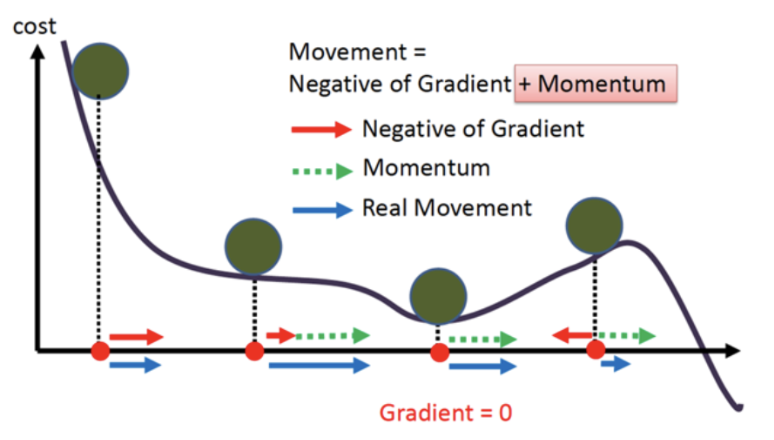
  - <span style="color:red">빨간 화살표</span> : 경사하강법이 이동하려는 방향 (현재 기울기)
  - <span style="color:green">초록 화살표</span> : 이전 단계의 이동을 반영한 방향 (관성)
  - <span style="color:blue">파란 화살표</span> : 실제 이동 방향 (둘의 합)
- **효과**
  - **Local Minima**를 관성의 힘으로 탈출 가능
  - 기울기가 매우 작은 구간도 빠르게 통과
- 코드
    ```python
    tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
    ```

#### 2. **알엠에스프롭 (RMSProp)**
- 기존 경사하강법은 기울기가 **큰 방향에서는 너무 많이, 작은 방향에서는 너무 조금** 이동
  - **각 방향마다 학습률을 따로 조정** -> 안정적이고 빠르게 학습
- 방법 : **최근 기울기를 참고**
  - **급한 경사**에서는 속도를 줄이고
  - **완만한 경사**에서는 속도 유지 or 증가
- 기존 경사하강법은 무조건 현재 기울기만 본다는 점과 대비!

#### 3. **아담 (Adam)**
- <span style="background-color:yellow; color:#000000; padding:0px; border-radius:5px;"> RMSProp + Momentum </span> -> **방향과 학습률(보폭)을 모두** 고려
- 각 파라미터의 **1차 모멘트**(기울기의 평균), **2차 모멘트**(기울기의 제곱 평균)를 사용해 학습률 조정
- 옵티마이저는 `compile()`의 `optimizer` 인자로 지정 (문자열 `'adam'`으로 써도 작동)
    ```python
    adam = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)
    model.compile(loss='categorical_crossentropy', optimizer=adam, metrics=['acc'])

    # 짧게 써도 됨
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['acc'])
    ```

#### 4. **결론!!! 그래서 뭘 쓸까??**

|               이럴 때              | 이걸 쓰기 |                  왜                  |
|:----------------------------------:|:---------:|:------------------------------------:|
| 잘 모르겠다 / 대부분의 경우        | **Adam**  | 방향과 보폭을 둘 다 잡음, 사실상 기본값 |
| 학습이 자꾸 한쪽으로 튄다          | 모멘텀    | 방향을 안정화                        |
| 파라미터마다 기울기 크기 차이가 큼 | RMSProp   | 방향별로 학습률을 따로 조정          |

- 결론 : **일단 Adam으로 시작**, 잘 안 되면 그때 바꾸기
- **정리**
  - 모멘텀 = **방향** 개선
  - RMSProp = **보폭(학습률)** 개선
  - Adam = 둘 다 (모멘텀 + RMSProp)